Last updated April 24, 2026

In [1]:
# plotting
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

import numpy as np
import pandas as pd

# sklearn
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# scipy
from scipy.optimize import nnls

In [2]:
root_dir = "/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/Projects/Jackie_post-mortem/"
tensor_dir = root_dir + "Results/tensor_decomposition/Sussman_2024_pHGG/l1_top_10000_vf/non_negative_parafac_5000_iter_tolerance_e_32_n=100_1_to_15_seed_777/3 runs combined/lof 0.05 20 neighbors/"
classifier_input_dir = root_dir + "/ProcessedData/Classifier/input/"
classifier_output_dir = root_dir + "/ProcessedData/Classifier/output/"

dataset_id =  "my_data"  # phgg, my_data, or herring2022

uncertain_label = "Unassigned"

In [3]:
# read in gene factors from 3D tensor decomposition
# dataframe is gene by factor (rank 8) and value is factor loading
gene_facs_df = pd.read_csv(tensor_dir + "rank_8/" + "gene_factors.tsv", sep = "\t")
gene_facs_df.index = gene_facs_df["Factor gene"]
gene_facs_df = gene_facs_df.drop('Factor gene', axis=1)
gene_facs_df = gene_facs_df[["Factor 1", "Factor 2", "Factor 3", "Factor 4", "Factor 5", "Factor 6", "Factor 7", "Factor 8"]]

H_df = gene_facs_df.T
H_df.index = ['Malignant', 'Neurons', 'Vascular', 'Glial', 'Immune', 'Glial2', 'Postmortem', 'Living']

In [4]:
H_df.head()

Factor gene,FLT1,FLI1,ST18,APBB1IP,CHI3L1,SLCO2B1,EBF1,NRG1,UTY,NKAIN2,...,MRPS5,PI16,FAM32A,CDC42BPA,PEF1,RBMX2,AIFM1,RPS6KB1,GPR137,GRIN2C
Malignant,6.016546e-03,6.423294e-03,8.008680e-03,7.704698e-03,0.009197,7.637263e-03,0.009766,0.011775,0.009689,0.010542,...,0.011132,4.238954e-03,0.008778,0.012637,0.008759,9.052423e-03,0.009528,0.010698,0.009352,5.903444e-03
Neurons,1.228396e-03,2.590848e-03,9.424550e-03,7.268664e-03,0.007024,2.020183e-03,0.015531,0.023328,0.006323,0.020588,...,0.014781,3.435140e-04,0.006837,0.021888,0.000529,1.410640e-03,0.001441,0.008358,0.004037,2.895281e-03
Vascular,2.222687e-02,2.137683e-02,9.978682e-38,1.461839e-38,0.003589,1.763218e-02,0.021131,0.001957,0.013887,0.005344,...,0.014853,1.431374e-293,0.002646,0.021308,0.003122,3.202691e-32,0.000721,0.010755,0.006123,5.540335e-23
Glial,1.388880e-218,2.503939e-147,1.474571e-02,5.798144e-03,0.006510,5.934457e-62,0.004487,0.010666,0.009982,0.012600,...,0.013585,6.982779e-03,0.006585,0.016901,0.004251,8.352272e-03,0.006741,0.011386,0.011734,7.021895e-04
Immune,9.323376e-03,1.554741e-02,1.267802e-02,1.636828e-02,0.004801,1.590771e-02,0.002027,0.010894,0.008026,0.007742,...,0.012801,2.003390e-04,0.006760,0.011986,0.007303,7.310461e-03,0.008451,0.011399,0.010531,9.019617e-10


In [5]:
# read in single-cell data
single_cell_data = pd.read_csv(classifier_input_dir + dataset_id + "_data.tsv", sep = "\t") # cell by gene
single_cell_metadata = pd.read_csv(classifier_input_dir + dataset_id + "_metadata.tsv", sep = "\t")
single_cell_metadata["cell_barcode"] = single_cell_metadata.index

# true labels
single_cell_metadata["y_true"] = single_cell_metadata["annotation"]

X_df = single_cell_data

/var/folders/7g/18hys0lj575f5mg2s5ymy3n80000gp/T/ipykernel_67345/431720180.py:3: DtypeWarning: Columns (17,21,22,25,90,94,95,98) have mixed types. Specify dtype option on import or set low_memory=False.
  single_cell_metadata = pd.read_csv(classifier_input_dir + dataset_id + "_metadata.tsv", sep = "\t")


In [6]:
X_df.head()

,AC109466.1,AC060765.2,AC016687.2,HBB,PLOD2,THSD7B,AC008415.1,ADAMTSL1,HTR2C,IL1RAPL2,...,AP002856.2,MAP9,AC011507.1,RGS9,AC126177.3,ADCYAP1R1,AC096589.1,TEX2,AC092353.1,AL592429.2
P1 A3_AAACCAAAGCAATCCA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.204856,0.0,0.000000,...,0.0,4.204856,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
P1 A3_AAACCCGCAATTACGA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,...,0.0,5.300721,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
P1 A3_AAACCCGCACCATAGG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,5.962543,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
P1 A3_AAACCCTGTTCCCAAG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
P1 A3_AAACGATGTCCATTCC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
set(single_cell_metadata["y_true"])

{'Glial', 'Immune', 'Neurons', 'Vascular'}

In [8]:
def row_norm(mat, mode="l2", eps=1e-12):
    if mode is None:
        return mat
    if mode == "l2":
        d = np.linalg.norm(mat, axis=1, keepdims=True)
    elif mode == "sum":
        d = mat.sum(axis=1, keepdims=True)
    else:
        raise ValueError("mode must be None, 'l2', or 'sum'")
    d = np.where(d < eps, 1.0, d)
    return mat / d

def nnls_W(X: np.ndarray, H: np.ndarray):
    A = H.T
    W = np.zeros((X.shape[0], H.shape[0]), dtype=float)
    for i in range(X.shape[0]):
        W[i], _ = nnls(A, X[i])
    return W

def to_props(W: np.ndarray, eps=1e-12):
    s = W.sum(axis=1, keepdims=True)
    s = np.where(s < eps, 1.0, s)
    return W / s


def compute_gene_weights(X_df, mode="inv_mean", eps=1e-12):
    X = X_df.values.astype(float)
    n_cells = X.shape[0]
    if mode == "inv_mean":
        s = X.mean(axis=0); w = 1.0 / np.clip(s, eps, None)
    elif mode == "inv_l2":
        s = np.sqrt((X**2).mean(axis=0)); w = 1.0 / np.clip(s, eps, None)
    elif mode == "idf":
        nz = (X > 0).sum(axis=0)
        w = np.log1p(n_cells) - np.log1p(nz)
        w = w / (w.max() + eps)
    elif mode == "none":
        w = 1
    else:
        raise ValueError("mode must be 'inv_mean', 'inv_l2', or 'idf'")
    return pd.Series(w, index=X_df.columns)



def topk_by_H(H_df, k=1000):
    H_masked = H_df.copy()
    for f in H_df.index:
        keep = H_df.loc[f].nlargest(k).index
        H_masked.loc[f, ~H_df.columns.isin(keep)] = 0.0
    return H_masked

def classify_with_argmax(
    X_df: pd.DataFrame,
    H_df: pd.DataFrame,
    y_true=None,
    fit_factors=None,
    classify_factors=None,
    gene_weighting=None,
    k_top=None,
    uncertain_band=None
):
    # --- Align genes
    common = X_df.columns.intersection(H_df.columns)
    X_df = X_df.loc[:, common]
    H_df = H_df.loc[:, common]

    # --- Gene weighting
    if gene_weighting is not None:
        w = compute_gene_weights(X_df, mode=gene_weighting)
        X_df = X_df.mul(w, axis=1)
        H_df = H_df.mul(w, axis=1)

    # --- Gene selection (top H only)
    if k_top is not None:
        H_df = topk_by_H(H_df, k=k_top)

    # --- Factors
    H_fit = H_df # fit on all factors

    # --- NNLS fit   
    X_mat = row_norm(X_df.values.astype(float), mode="l2")
    Hn_fit = row_norm(H_fit.values.astype(float), mode="l2")
    #X_mat = X_df.values.astype(float)
    #Hn_fit = H_fit.values.astype(float)
    W_full = nnls_W(X_mat, Hn_fit)
    W_prop_all = pd.DataFrame(to_props(W_full), index=X_df.index, columns=H_fit.index)
    W_prop_cls = W_prop_all[classify_factors]
   
    # --- Classification based on argmax
    labels_initial = W_prop_cls.idxmax(axis=1)
    labels_final = labels_initial.copy()

    # --- Optional: classify as uncertain
    if uncertain_band is not None:
        for cell in W_prop_cls.index:
            vals = W_prop_cls.loc[cell].values
            margin = (np.sort(vals)[-1] - np.sort(vals)[-2]) if len(vals) > 1 else vals[0]
            if margin < uncertain_band:
                labels_final.loc[cell] = uncertain_label


    return {
        "W_prop_all": W_prop_all,
        "W_prop_cls": W_prop_cls,
        "labels_initial": labels_initial,
        "labels_final": labels_final
    }


In [9]:
k_top_use = 1000

results = classify_with_argmax(
    X_df, H_df,
    k_top=k_top_use, 
    gene_weighting="idf", # "inv_mean" or "idf" or "inv_l2" or "none"
    uncertain_band=0.2,
    fit_factors=H_df.index.to_list(), # fit with all factors
    classify_factors=["Glial", "Immune", "Neurons", "Vascular"],
)

In [10]:
single_cell_metadata["labels_initial"] = results["labels_initial"] 
single_cell_metadata["labels_final"] = results["labels_final"] # with uncertainty mask

In [11]:
single_cell_metadata["labels_final"].value_counts()

labels_final
Glial         37776
Unassigned    20780
Neurons       19020
Immune         6135
Vascular        432
Name: count, dtype: int64

In [12]:
def evaluate_predictions(
    df,
    true_col="y_true",
    pred_initial_col="labels_initial",
    pred_final_col="labels_final",
    high_quality_only=False,
    score_mode="initial",  # "initial" or "final"
    exclude_true_labels=("Filtered out", "Poor quality"),
    uncertain_label=uncertain_label
):
    """
    score_mode behavior:
      - 'initial': confusion matrix + scoring use labels_initial
      - 'final'  : confusion matrix uses labels_final (shows Uncertain),
                   scoring excludes Uncertain
    """

    # ---------------- Base filtering ----------------
    df_base = df.copy()
    if high_quality_only:
        df_base = df_base[df_base["low.quality.by.qc"] == False]

    # ---------------- Choose prediction column ----------------
    if score_mode == "initial":
        pred_col_display = pred_initial_col
        pred_col_score = pred_initial_col

        scoring_mask = ~df_base[true_col].isin(exclude_true_labels)

    elif score_mode == "final":
        pred_col_display = pred_final_col
        pred_col_score = pred_final_col

        scoring_mask = (
            (df_base[pred_final_col] != uncertain_label) &
            (~df_base[true_col].isin(exclude_true_labels))
        )
    else:
        raise ValueError("score_mode must be 'initial' or 'final'")

    # ---------------- Confusion matrix (DISPLAY) ----------------
    y_true_display = df_base[true_col]
    y_pred_display = df_base[pred_col_display]
    
    labels_all = sorted(set(y_true_display) | set(y_pred_display))
    cm = confusion_matrix(y_true_display, y_pred_display, labels=labels_all)
    cm_df = pd.DataFrame(cm, index=labels_all, columns=labels_all)

    # ---------------- Scoring ----------------
    df_score = df_base[scoring_mask]

    accuracy = accuracy_score(
        df_score[true_col],
        df_score[pred_col_score]
    )

    report = classification_report(
        df_score[true_col],
        df_score[pred_col_score]
    )

    return cm_df, accuracy, report, df_base, df_score

In [13]:
def plot_confusion_matrix(
    cm_df,
    title="Confusion Matrix",
    figsize=(8, 6),
    cmap="Blues",
    tick_label_size=16,
    axis_label_size=16,
    title_size=16,
    save_path = None
):
    plt.figure(figsize=figsize)

    # Automatically detect if data is float (normalized) or int (raw counts)
    is_float = np.issubdtype(cm_df.values.dtype, np.floating)
    fmt_str = ".2f" if is_float else "d"

    ax = sns.heatmap(
        cm_df,
        annot=True,
        fmt=fmt_str,
        cmap=cmap,
        cbar=True
    )

    # Axis labels
    ax.set_xlabel("Predicted label", fontsize=axis_label_size)
    ax.set_ylabel("True label", fontsize=axis_label_size)

    # Tick labels
    ax.tick_params(axis="x", labelsize=tick_label_size, rotation=45)
    ax.tick_params(axis="y", labelsize=tick_label_size, rotation=0)

    # Title
    ax.set_title(title, fontsize=title_size)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)
    plt.show()

In [14]:
def prepare_confusion_matrix_for_plot(
    cm_df,
    hide_pred_labels=(),
    hide_true_labels=(),
    bottom_true_labels=("Poor quality", "Filtered out"),
    bottom_pred_labels=(uncertain_label,),  # Added this for x-axis
    normalize=True
):
    cm_plot = cm_df.copy()

    # 1. Drop prediction labels (columns)
    cols_to_drop = [lbl for lbl in hide_pred_labels if lbl in cm_plot.columns]
    if cols_to_drop:
        cm_plot = cm_plot.drop(columns=cols_to_drop)

    # 2. Drop true labels (rows)
    rows_to_drop = [lbl for lbl in hide_true_labels if lbl in cm_plot.index]
    if rows_to_drop:
        cm_plot = cm_plot.drop(index=rows_to_drop)

    # 3. Reorder Rows (y-axis)
    rows = list(cm_plot.index)
    top_rows = [r for r in rows if r not in bottom_true_labels]
    bottom_rows = [r for r in bottom_true_labels if r in rows]
    cm_plot = cm_plot.loc[top_rows + bottom_rows]

    # 4. Reorder Columns (x-axis) - NEW LOGIC
    cols = list(cm_plot.columns)
    left_cols = [c for c in cols if c not in bottom_pred_labels]
    right_cols = [c for c in bottom_pred_labels if c in cols]
    cm_plot = cm_plot[left_cols + right_cols]

    # 5. Normalize AFTER reordering/dropping
    if normalize:
        row_sums = cm_plot.sum(axis=1)
        cm_plot = cm_plot.div(row_sums + 1e-9, axis=0)

    return cm_plot

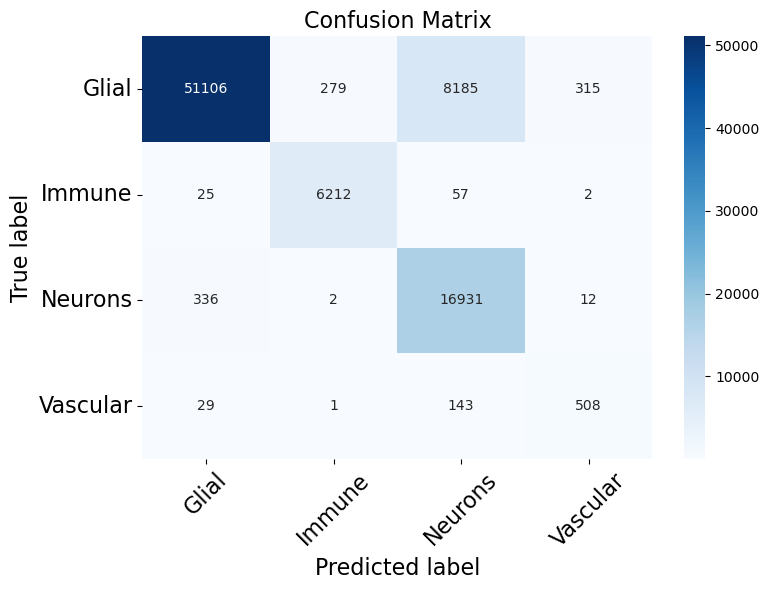

              precision    recall  f1-score   support

       Glial       0.99      0.85      0.92     59885
      Immune       0.96      0.99      0.97      6296
     Neurons       0.67      0.98      0.79     17281
    Vascular       0.61      0.75      0.67       681

    accuracy                           0.89     84143
   macro avg       0.81      0.89      0.84     84143
weighted avg       0.92      0.89      0.89     84143



In [15]:
# All data showing all labels

cm_df, acc, report, df_display, df_score = evaluate_predictions(
    single_cell_metadata,
    high_quality_only=False,
    score_mode="initial"
)
cm_plot = prepare_confusion_matrix_for_plot(
    cm_df,
    hide_pred_labels=("Filtered out", "Poor quality"),
    hide_true_labels=(),
    normalize=False
)

plot_confusion_matrix(cm_plot, save_path = root_dir + "Figures/Figure 2/Classifier/" + dataset_id + "_confusion_matrix_initial.pdf")


print(report)

with open(root_dir + "Figures/Figure 2/Classifier/" + dataset_id + "_report_initial.txt", "w") as f:
  f.write(report)

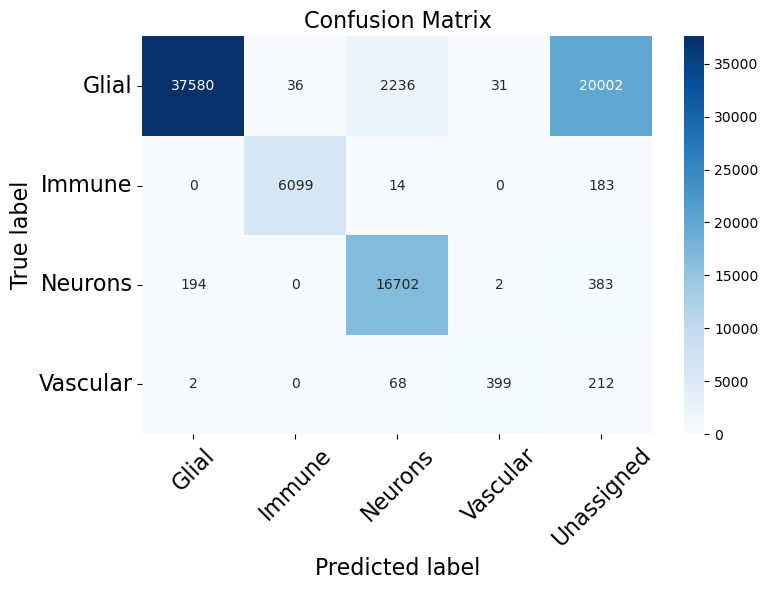

              precision    recall  f1-score   support

       Glial       0.99      0.94      0.97     39883
      Immune       0.99      1.00      1.00      6113
     Neurons       0.88      0.99      0.93     16898
    Vascular       0.92      0.85      0.89       469

    accuracy                           0.96     63363
   macro avg       0.95      0.94      0.94     63363
weighted avg       0.96      0.96      0.96     63363



In [16]:
# All data showing all labels with uncertain predictions

cm_df, acc, report, df_display, df_score = evaluate_predictions(
    single_cell_metadata,
    high_quality_only=False,
    score_mode="final"
)
cm_plot = prepare_confusion_matrix_for_plot(
    cm_df,
    hide_pred_labels=("Filtered out", "Poor quality"),
    hide_true_labels=(uncertain_label,),
    normalize=False
)

plot_confusion_matrix(cm_plot, save_path = root_dir + "Figures/Figure 2/Classifier/" + dataset_id + "_confusion_matrix_final_w_uncertain.pdf")


print(report)

with open(root_dir + "Figures/Figure 2/Classifier/" + dataset_id + "_report_final_w_uncertain.txt", "w") as f:
  f.write(report)

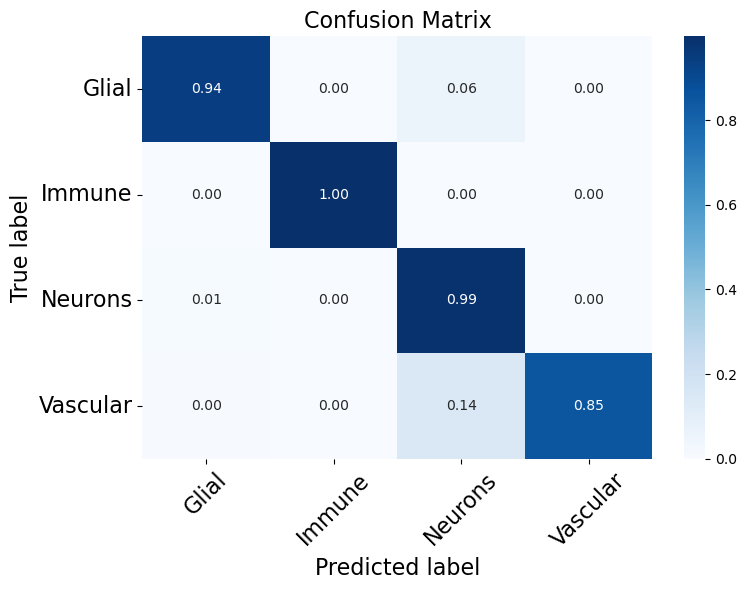

              precision    recall  f1-score   support

       Glial       0.99      0.94      0.97     39883
      Immune       0.99      1.00      1.00      6113
     Neurons       0.88      0.99      0.93     16898
    Vascular       0.92      0.85      0.89       469

    accuracy                           0.96     63363
   macro avg       0.95      0.94      0.94     63363
weighted avg       0.96      0.96      0.96     63363



In [17]:
# Only high-certainty predictions
cm_df, acc, report, df_display, df_score = evaluate_predictions(
    single_cell_metadata,
    high_quality_only=False,
    score_mode="final"
)
cm_plot = prepare_confusion_matrix_for_plot(
    cm_df,
    hide_pred_labels=("Filtered out", "Poor quality", uncertain_label),
    hide_true_labels=("Filtered out", "Poor quality", uncertain_label)
)

plot_confusion_matrix(cm_plot, save_path = root_dir + "Figures/Figure 2/Classifier/" + dataset_id + "_confusion_matrix_final_certain.pdf")


print(report)


with open(root_dir + "Figures/Figure 2/Classifier/" + dataset_id + "_report_final_certain.txt", "w") as f:
  f.write(report)


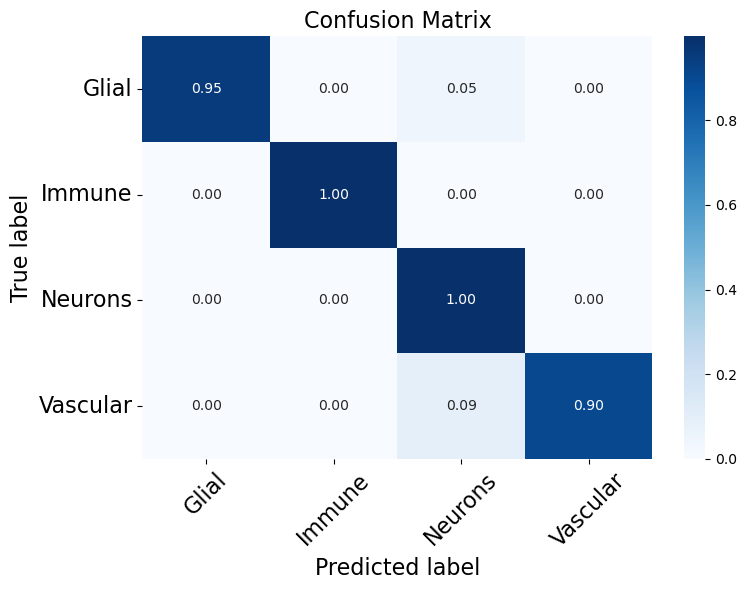

              precision    recall  f1-score   support

       Glial       1.00      0.95      0.97     38529
      Immune       1.00      1.00      1.00      5554
     Neurons       0.87      1.00      0.93     12622
    Vascular       0.94      0.90      0.92       357

    accuracy                           0.97     57062
   macro avg       0.95      0.96      0.96     57062
weighted avg       0.97      0.97      0.97     57062



In [18]:
# Only high-quality cells and high-certainty predictions
cm_df, acc, report, df_display, df_score = evaluate_predictions(
    single_cell_metadata,
    high_quality_only=True,
    score_mode="final"
)
cm_plot = prepare_confusion_matrix_for_plot(
    cm_df,
    hide_pred_labels=("Filtered out", "Poor quality", uncertain_label),
    hide_true_labels=("Filtered out", "Poor quality", uncertain_label),
    normalize = True
)

plot_confusion_matrix(cm_plot, save_path = root_dir + "Figures/Figure 2/Classifier/" + dataset_id + "_confusion_matrix_final_certain_high_quality.pdf")


print(report)


with open(root_dir + "Figures/Figure 2/Classifier/" + dataset_id + "_report_final_certain_high_quality.txt", "w") as f:
  f.write(report)


In [19]:
# save predictions
predictions_df = pd.DataFrame({"labels_final": results["labels_final"].to_list(),
                               "labels_initial": results["labels_initial"].to_list()})
predictions_df.index = results["labels_final"].index.to_list()
predictions_df.to_csv(classifier_output_dir + dataset_id + "_predictions.tsv", sep = "\t")

In [20]:
dataset_id

'my_data'

In [21]:
classifier_output_dir

'/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/Projects/Jackie_post-mortem//ProcessedData/Classifier/output/'